<h1> Milestone 3 - Workshop </h1>

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

In [3]:
#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True

<h3> What needs to be done </h3>

We have 3 datasets of the 5 in our section of Aviation System Performance that we want to examine for our airline departure delay problem: Can we find the factors that exhibit the most significant impact on a flight NOT operating on schedule? Examining weather-related and non weather-related delay factors.

- 2015 Flight Delay + Cancellations Dataset: https://www.kaggle.com/datasets/usdot/flight-delays
- 2019 Flight Delay + Causes Dataset: https://www.kaggle.com/datasets/undersc0re/flight-delay-and-causes
- 2019 Flight Delay Dataset + Weather: https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations

For each dataset, we want to:

- Preprocess (Identifying and handling missing values/duplicate rows, encoding categorical variables, standardizing units, assessing if datasets can be merged, filtering unrealistic values)
- Univariate Analysis (Histograms and their variants, grouped histograms by variable, outlier detection, bar plots for categorical variables)
- Bivariate Analysis (Correlations, scatterplots on variables with large correlations, possible time series applications, grouped means/medians/modes)

These will fuel our conclusions:

- What aspects of the data were unexpected?
- Will we need to disqualify any datasets because of problems we uncovered in the data? Can these datasets be merged?
- What kind of supervised/unsupervised analyses are suggested by your work? (Depending on the target variable, this could be regression OR classification)

Some other helpful guidelines:

- You should include 6-8 figures/graphs in the body of the paper (size-wise, a single page should fit 6 figures), so be sure to generate as much as you can first then scale down

<h3> Dataset Downloads </h3>

In [7]:
d19 = pd.read_csv('Flight_delay_2019H1.csv', low_memory = False)
d19.info()

<class 'pandas.DataFrame'>
RangeIndex: 484551 entries, 0 to 484550
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DayOfWeek          484551 non-null  int64
 1   Date               484551 non-null  str  
 2   DepTime            484551 non-null  int64
 3   ArrTime            484551 non-null  int64
 4   CRSArrTime         484551 non-null  int64
 5   UniqueCarrier      484551 non-null  str  
 6   Airline            484551 non-null  str  
 7   FlightNum          484551 non-null  int64
 8   TailNum            484551 non-null  str  
 9   ActualElapsedTime  484551 non-null  int64
 10  CRSElapsedTime     484551 non-null  int64
 11  AirTime            484551 non-null  int64
 12  ArrDelay           484551 non-null  int64
 13  DepDelay           484551 non-null  int64
 14  Origin             484551 non-null  str  
 15  Org_Airport        483374 non-null  str  
 16  Dest               484551 non-null  str  
 17  De

<h2> Dataset: 2019 Flight Delays and Causes</h2>

<h3>Data Dictionary</h3>

- DayOfWeek → 1 (Monday) - 7 (Sunday)
- Date → Scheduled date
- DepTime → Actual departure time (local, hhmm)
- ArrTime → Actual arrival time (local, hhmm)
- CRSArrTime → Scheduled arrival time (local, hhmm)
- UniqueCarrier → Unique carrier code
- Airline → Airline company
- FlightNum → flight number
- TailNum → plane tail number
- ActualElapsedTime → Actual time an airplane spends in the air(in minutes) with TaxiIn/Out
- CRSElapsedTime → CRS Elapsed Time of Flight (estimated elapse time), in minutes
- AirTime → Flight Time (in minutes)
- ArrDelay → Difference in minutes between scheduled and actual arrival time
- Origin → Origin IATA(International Air Transport Association) airport code
- Org_Airport → Origin Airport Name
- Dest → Destination IATA code
- Dest_Airport → Destination Airport Name
- Distance → Distance between airports (miles)
- TaxiIn → Wheels down and arrival at the destination airport gate, in minutes
- TaxiOut → The time elapsed between departure from the origin airport gate and wheels off, in minutes
- Cancelled → Was the flight canceled?
- CancellationCode → Reason for cancellation
- Diverted → 1 = yes, 0 = no
- CarrierDelay → Flight delay due to carrier(e.g. maintenance or crew problems, aircraft cleaning, fueling, etc), 0 = No, yes = (in minutes)
- WeatherDelay → Flight delay due to weather, 0 = No, yes = (in minutes)
- NASDelay → Flight delay by NSA(National Aviation System), 0 = No, yes = (in minutes)
- SecurityDelay → Flight delay by this reason, 0 = No, yes = (in minutes)
- LateAircraftDelay → Flight delay by this reason, 0 = No, yes = (in minutes)

In [11]:
all19 = d19.copy()

<h3> Preprocessing </h3>

In [13]:
all19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,4,03-01-2019,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,3,10,0,N,0,2,0,0,0,32
1,4,03-01-2019,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,3,7,0,N,0,10,0,0,0,47
2,4,03-01-2019,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,6,8,0,N,0,8,0,0,0,72
3,4,03-01-2019,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,7,8,0,N,0,3,0,0,0,12
4,4,03-01-2019,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,4,9,0,N,0,0,0,0,0,16


In [14]:
all19.info()

<class 'pandas.DataFrame'>
RangeIndex: 484551 entries, 0 to 484550
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DayOfWeek          484551 non-null  int64
 1   Date               484551 non-null  str  
 2   DepTime            484551 non-null  int64
 3   ArrTime            484551 non-null  int64
 4   CRSArrTime         484551 non-null  int64
 5   UniqueCarrier      484551 non-null  str  
 6   Airline            484551 non-null  str  
 7   FlightNum          484551 non-null  int64
 8   TailNum            484551 non-null  str  
 9   ActualElapsedTime  484551 non-null  int64
 10  CRSElapsedTime     484551 non-null  int64
 11  AirTime            484551 non-null  int64
 12  ArrDelay           484551 non-null  int64
 13  DepDelay           484551 non-null  int64
 14  Origin             484551 non-null  str  
 15  Org_Airport        483374 non-null  str  
 16  Dest               484551 non-null  str  
 17  De

<h3> Duplicate Rows, Missing Values</h3>

In [16]:
dupes_19 = all19[all19.duplicated()]
dupes_19

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
145746,4,28-02-2019,1854,1946,1902,F9,Frontier Airlines Inc.,773,N201FR,112,...,8,13,0,N,0,44,0,0,0,0
145748,4,28-02-2019,2027,2314,2229,F9,Frontier Airlines Inc.,780,N201FR,107,...,10,13,0,N,0,1,0,44,0,0


In [17]:
#get rid of the null origin/destination airport values

all19 = all19.dropna()

In [18]:
all19.info()

<class 'pandas.DataFrame'>
Index: 481895 entries, 0 to 484550
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DayOfWeek          481895 non-null  int64
 1   Date               481895 non-null  str  
 2   DepTime            481895 non-null  int64
 3   ArrTime            481895 non-null  int64
 4   CRSArrTime         481895 non-null  int64
 5   UniqueCarrier      481895 non-null  str  
 6   Airline            481895 non-null  str  
 7   FlightNum          481895 non-null  int64
 8   TailNum            481895 non-null  str  
 9   ActualElapsedTime  481895 non-null  int64
 10  CRSElapsedTime     481895 non-null  int64
 11  AirTime            481895 non-null  int64
 12  ArrDelay           481895 non-null  int64
 13  DepDelay           481895 non-null  int64
 14  Origin             481895 non-null  str  
 15  Org_Airport        481895 non-null  str  
 16  Dest               481895 non-null  str  
 17  Dest_Ai

<h3> Creating TotalDelay Column </h3>

In [20]:
all19['TotalDelay'] = all19.ActualElapsedTime - all19.CRSElapsedTime

In [21]:
all19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,TotalDelay
0,4,03-01-2019,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,10,0,N,0,2,0,0,0,32,0
1,4,03-01-2019,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,7,0,N,0,10,0,0,0,47,-10
2,4,03-01-2019,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,8,0,N,0,8,0,0,0,72,-14
3,4,03-01-2019,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,8,0,N,0,3,0,0,0,12,-12
4,4,03-01-2019,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,9,0,N,0,0,0,0,0,16,-12


In [22]:
all19.Cancelled.value_counts()

Cancelled
0    481895
Name: count, dtype: int64

In [23]:
all19 = all19.drop(['Cancelled', 'CancellationCode'], axis = 1)

First preprocessing steps:

- Created TotalDelay column
- There are no cancelled flights in this dataset
- Dropped null values (no origin/destination airport)

Final dataset size: 481,895 rows

<h3> Encoding Categorical Variables </h3>

In [26]:
#encoding AIRLINE

one_hot1 = pd.get_dummies(all19['UniqueCarrier'], prefix = 'Airline', dtype = int)
all19 = all19.join(one_hot1)
all19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,Airline_B6,Airline_DL,Airline_EV,Airline_F9,Airline_HA,Airline_MQ,Airline_OO,Airline_UA,Airline_US,Airline_WN
0,4,03-01-2019,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,0,0,0,0,0,0,0,0,0,1
1,4,03-01-2019,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,0,0,0,0,0,0,0,0,0,1
2,4,03-01-2019,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,0,0,0,0,0,0,0,0,0,1
3,4,03-01-2019,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,0,0,0,0,0,0,0,0,0,1
4,4,03-01-2019,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,0,0,0,0,0,0,0,0,0,1


In [27]:
all19[['Origin', 'Org_Airport', 'Dest', 'Dest_Airport']].head()

,Origin,Org_Airport,Dest,Dest_Airport
0,IND,Indianapolis International Airport,BWI,Baltimore-Washington International Airport
1,IND,Indianapolis International Airport,LAS,McCarran International Airport
2,IND,Indianapolis International Airport,MCO,Orlando International Airport
3,IND,Indianapolis International Airport,PHX,Phoenix Sky Harbor International Airport
4,IND,Indianapolis International Airport,TPA,Tampa International Airport


In [28]:
len(pd.unique(all19.Origin))

259

<h3> Adjusting the Date Variables </h3>

In [30]:
all19['Date'] = pd.to_datetime(all19['Date'], format = '%d-%m-%Y')

In [31]:
# day of week goes from 1 to 7, 1 being monday

# Define the mapping
day_mapping = {
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
}

# Use the .replace() method to map the numbers to text
all19['DayOfWeek'] = all19['DayOfWeek'].replace(day_mapping)

In [32]:
all19.head()

,DayOfWeek,Date,DepTime,ArrTime,CRSArrTime,UniqueCarrier,Airline,FlightNum,TailNum,ActualElapsedTime,...,Airline_B6,Airline_DL,Airline_EV,Airline_F9,Airline_HA,Airline_MQ,Airline_OO,Airline_UA,Airline_US,Airline_WN
0,Thursday,2019-01-03,1829,1959,1925,WN,Southwest Airlines Co.,3920,N464WN,90,...,0,0,0,0,0,0,0,0,0,1
1,Thursday,2019-01-03,1937,2037,1940,WN,Southwest Airlines Co.,509,N763SW,240,...,0,0,0,0,0,0,0,0,0,1
2,Thursday,2019-01-03,1644,1845,1725,WN,Southwest Airlines Co.,1333,N334SW,121,...,0,0,0,0,0,0,0,0,0,1
3,Thursday,2019-01-03,1452,1640,1625,WN,Southwest Airlines Co.,675,N286WN,228,...,0,0,0,0,0,0,0,0,0,1
4,Thursday,2019-01-03,1323,1526,1510,WN,Southwest Airlines Co.,4,N674AA,123,...,0,0,0,0,0,0,0,0,0,1


Second set of preprocessing steps:

- Encoded Airline variable
- Changed Date variable to timestamp
- Changed DayOfWeek from number to day

<h3>EDA - Univariate</h3>

<h3> Histograms and Other Variants </h3>

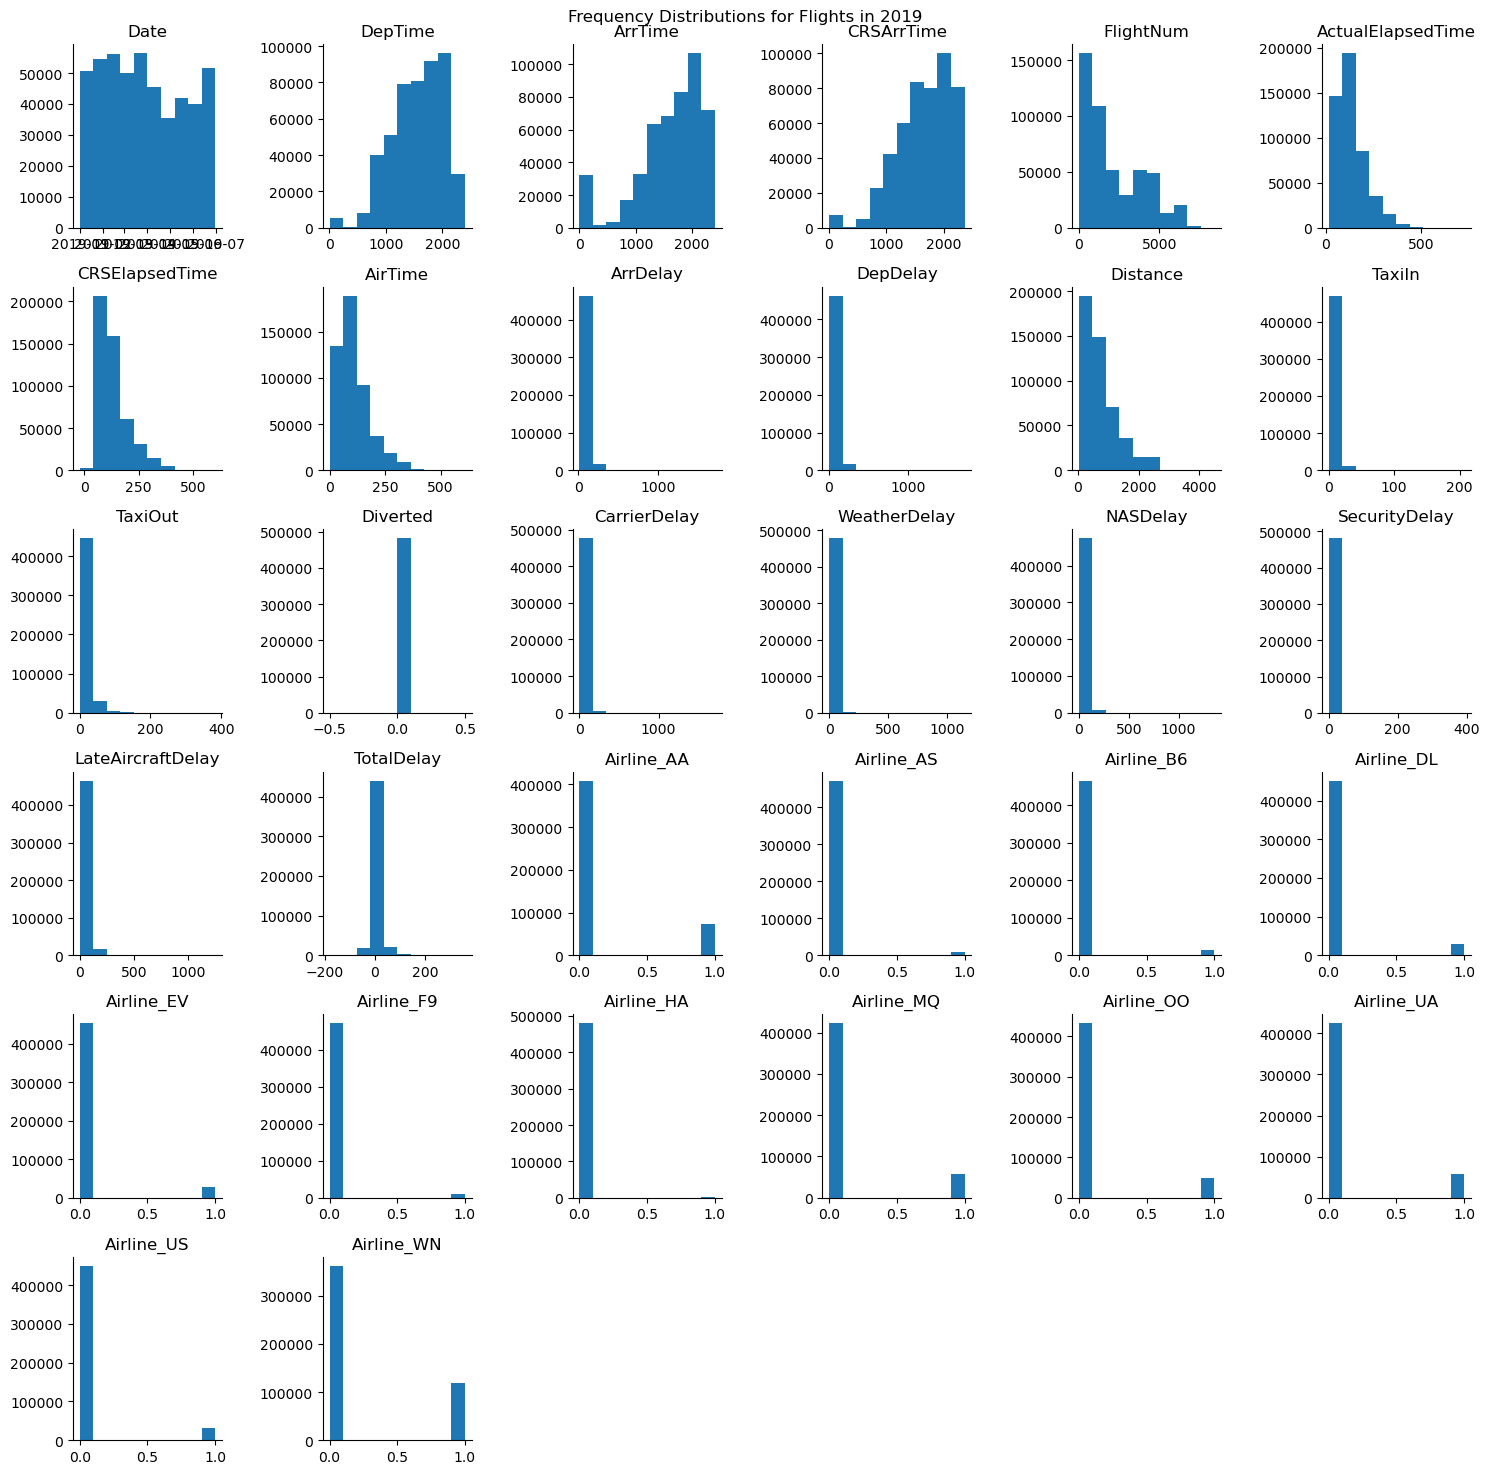

In [36]:
all19.hist(figsize=(15, 15), grid = False)
plt.suptitle('Frequency Distributions for Flights in 2019')
plt.tight_layout();

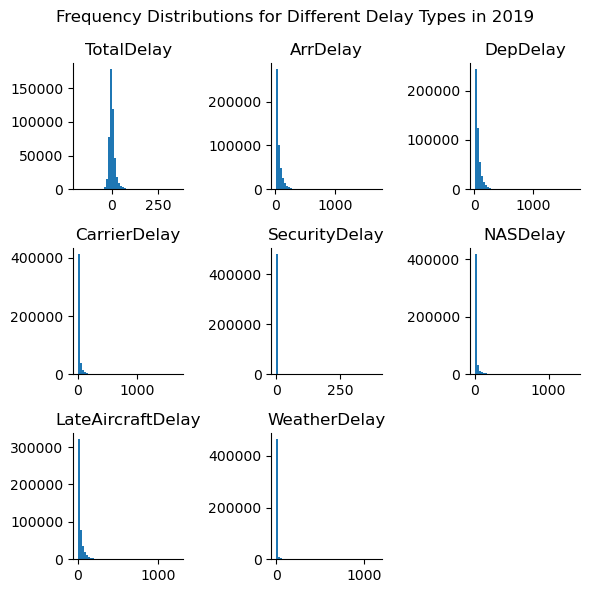

In [37]:
all19[['TotalDelay', 'ArrDelay', 'DepDelay', 'CarrierDelay', 'SecurityDelay', 'NASDelay', 'LateAircraftDelay', 
               'WeatherDelay']].hist(figsize=(6, 6), bins = 50, grid = False)
plt.suptitle('Frequency Distributions for Different Delay Types in 2019')
plt.tight_layout();

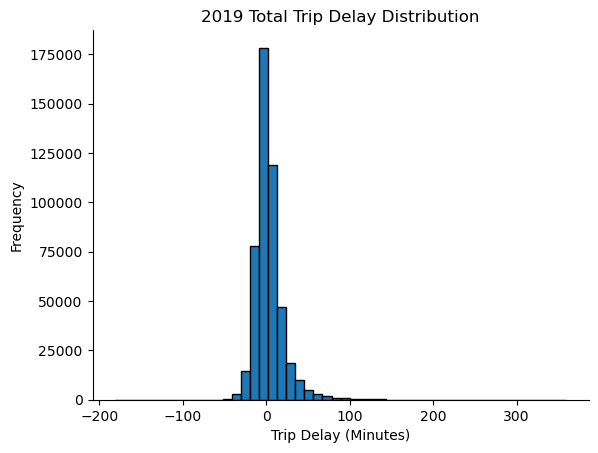

In [38]:
all19.hist('TotalDelay', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Trip Delay (Minutes)')
plt.ylabel('Frequency')
plt.title('2019 Total Trip Delay Distribution');

In [39]:
print('Max total delay:', max(all19.TotalDelay), 'minutes')
print('Min total delay:', min(all19.TotalDelay), 'minutes')

Max total delay: 359 minutes
Min total delay: -181 minutes


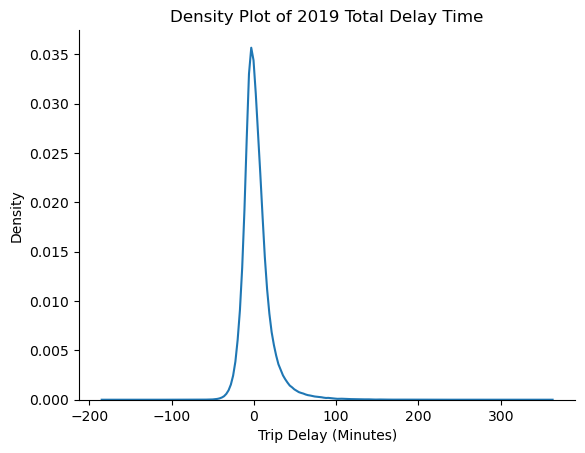

In [40]:
sns.kdeplot(all19.TotalDelay)
plt.xlabel('Trip Delay (Minutes)')
plt.ylabel('Density')
plt.title('Density Plot of 2019 Total Delay Time');

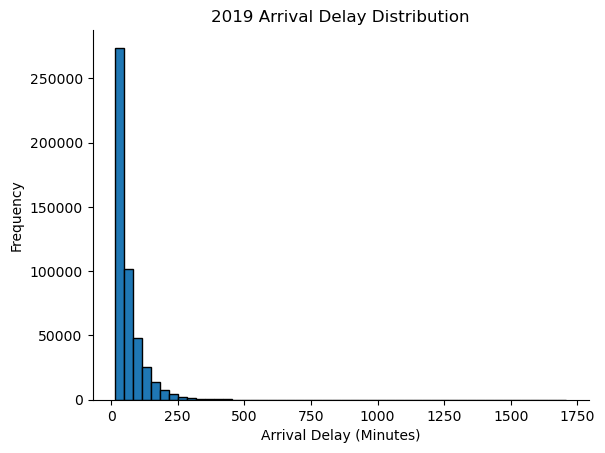

In [41]:
all19.hist('ArrDelay', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Arrival Delay (Minutes)')
plt.ylabel('Frequency')
plt.title('2019 Arrival Delay Distribution');

In [42]:
print('Max arrival delay:', max(all19.ArrDelay), 'minutes')
print('Min arrival delay:', min(all19.ArrDelay), 'minutes')

Max arrival delay: 1707 minutes
Min arrival delay: 15 minutes


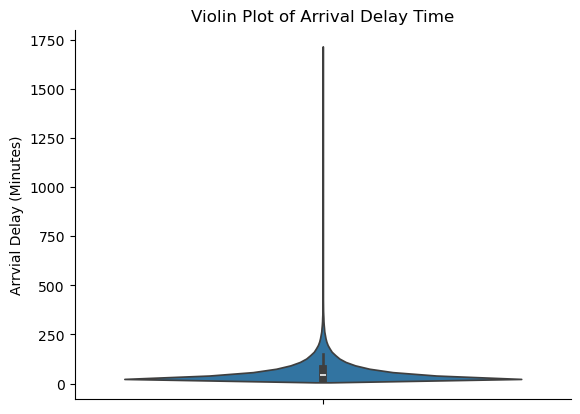

In [43]:
sns.violinplot(all19.ArrDelay)
plt.ylabel('Arrvial Delay (Minutes)')
plt.title('Violin Plot of Arrival Delay Time');

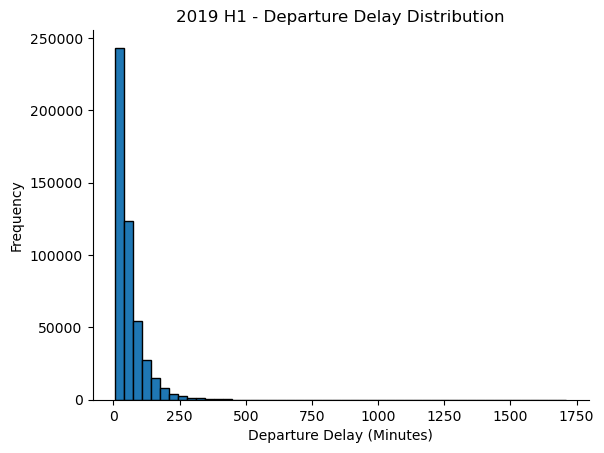

In [120]:
all19.hist('DepDelay', edgecolor = 'black', bins = 50, grid = False)
plt.xlabel('Departure Delay (Minutes)')
plt.ylabel('Frequency')
plt.title('2019 H1 - Departure Delay Distribution');

In [45]:
print('Max departure delay:', max(all19.DepDelay), 'minutes')
print('Min departure delay:', min(all19.DepDelay), 'minutes')

Max departure delay: 1710 minutes
Min departure delay: 6 minutes


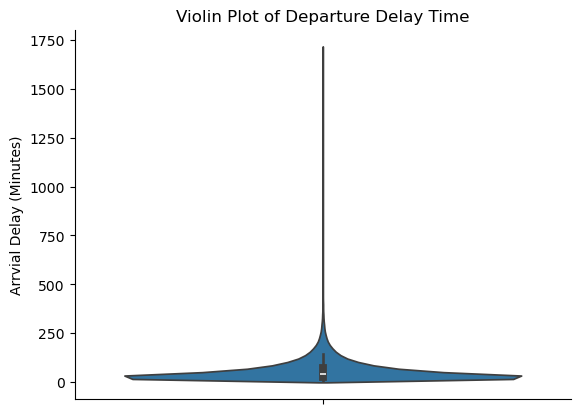

In [46]:
sns.violinplot(all19.DepDelay)
plt.ylabel('Arrvial Delay (Minutes)')
plt.title('Violin Plot of Departure Delay Time');

What we're seeing from histograms and density plots:

- Again, TotalDelay variable looks to be pretty normally distributed
- Unlike 2015, every flight has in this dataset has some type of delay, whether it be arrival or departure
- Arrival and departure delays both look pretty skewed right, indicative or small quantities of outlier values
- Likely multimodal distribution of flights in 2019 as well

<h3> Outlier Detection with Boxplots </h3>

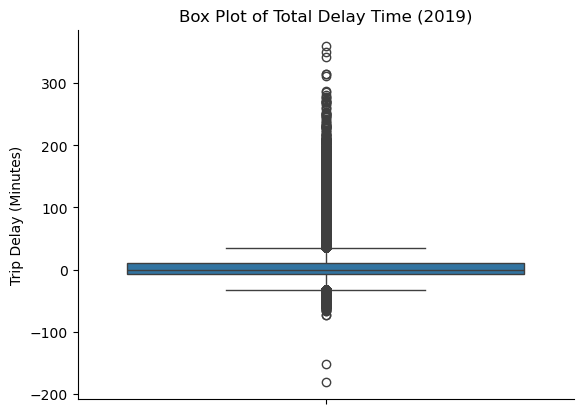

In [49]:
#Total Delay

sns.boxplot(all19.TotalDelay)
plt.ylabel('Trip Delay (Minutes)')
plt.title('Box Plot of Total Delay Time (2019)');

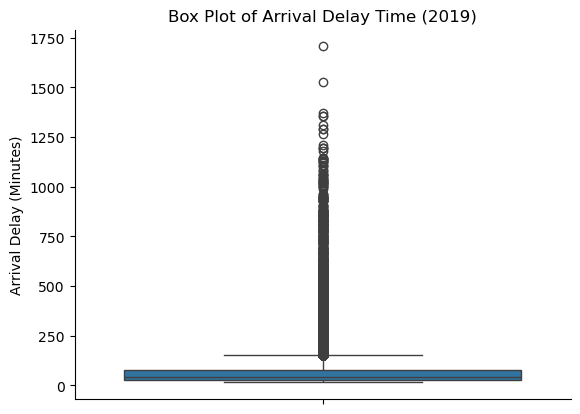

In [50]:
#Arrival Delay

sns.boxplot(all19.ArrDelay)
plt.ylabel('Arrival Delay (Minutes)')
plt.title('Box Plot of Arrival Delay Time (2019)');

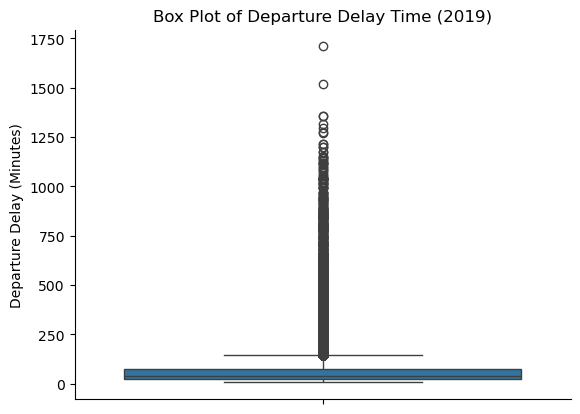

In [51]:
#Departure

sns.boxplot(all19.DepDelay)
plt.ylabel('Departure Delay (Minutes)')
plt.title('Box Plot of Departure Delay Time (2019)');

What we're seeing from the boxplots:

- All of our delay variables have outliers, standardization likely doesn't fix this either
- Modeling Note: implementing a random forest algorithm (which is less sensitive to outliers) could work well with this dataset

<h3> Bar Plots </h3>

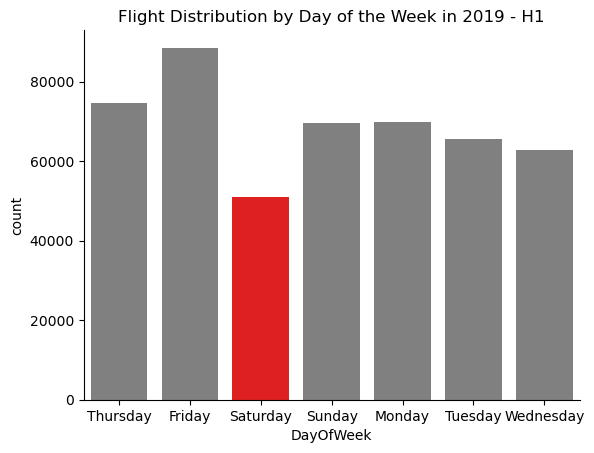

In [54]:
#day of week

colors = ['red' if day == 'Saturday' else "grey" for day in all19['DayOfWeek'].unique()]

sns.countplot(x= 'DayOfWeek', hue = 'DayOfWeek', data = all19, legend = False, palette = colors)
plt.title('Flight Distribution by Day of the Week in 2019 - H1')
plt.show();

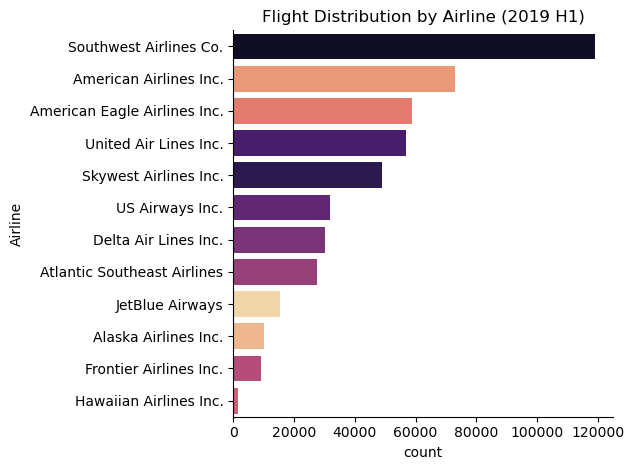

In [55]:
#Bar Plot showing total counts of airlines


ax = sns.countplot(y= 'Airline', hue = 'Airline', order=all19.Airline.value_counts().index,
              palette = 'magma', data = all19)


plt.ylabel('Airline')
plt.title('Flight Distribution by Airline (2019 H1)')
plt.tight_layout()
plt.show();

What we found from bar plots:

- Not as even distribution of flights by day of week in 2019 as there were in the 2015 dataset
- We see the least amount of flights in 2019 occur on Saturday again, but it's clearer this time at around 50,000
- Airlines by the top 5 number of flights: Southwest, American Airlines, American Eagle, United, Skywest

<h3> Means, Medians, Modes </h3>

In [58]:
means = all19[['TotalDelay', 'ArrDelay', 'DepDelay', 'CarrierDelay', 'SecurityDelay', 'NASDelay', 'LateAircraftDelay', 
               'WeatherDelay']].mean()
means

TotalDelay            3.413881
ArrDelay             60.877770
DepDelay             57.463873
CarrierDelay         17.334372
SecurityDelay         0.081574
NASDelay             13.600834
LateAircraftDelay    26.727366
WeatherDelay          3.133625
dtype: float64

In [59]:
medians = all19[['TotalDelay', 'ArrDelay', 'DepDelay', 'CarrierDelay', 'SecurityDelay', 'NASDelay', 'LateAircraftDelay', 
               'WeatherDelay']].median()
medians

TotalDelay            0.0
ArrDelay             42.0
DepDelay             40.0
CarrierDelay          2.0
SecurityDelay         0.0
NASDelay              1.0
LateAircraftDelay    13.0
WeatherDelay          0.0
dtype: float64

What we got from the means/medians report:

- The average total trip delay is positive this time around as opposed to 2015, meaning trips are late on average
- Arrival and departure delays are significantly larger than what we saw in 2015
- Late aircraft delay and carrier delays are have the 2 highest averages AND medians
- Should be noted though, this dataset seems to only have flights that are delayed, unlike 2015

<h3> EDA - Bivariate</h3>

In [62]:
number19= all19.drop(['DayOfWeek', 'Date', 'DepTime', 'ArrTime', 'CRSArrTime',
                     'UniqueCarrier', 'Airline', 'FlightNum', 'TailNum',
                     'Origin', 'Org_Airport', 'Dest', 'Dest_Airport',
                     'Diverted'], axis =1) #creating df of numeric columns only to run correlation matrix

corrs = number19.corr()

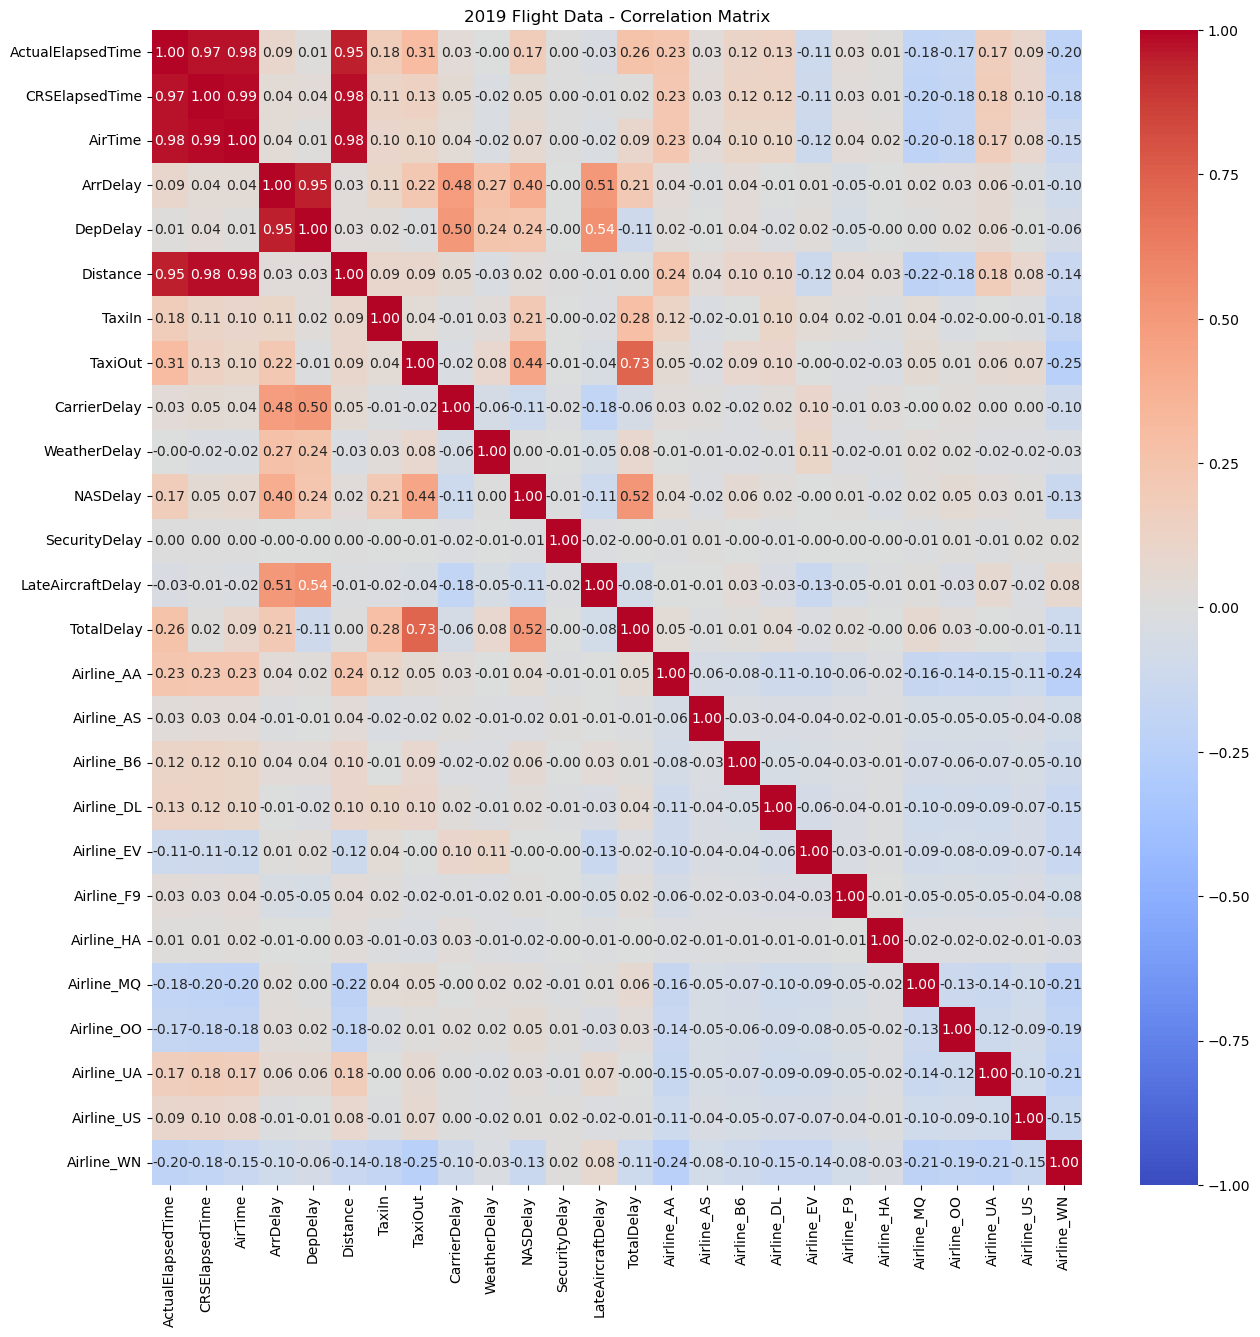

In [63]:
plt.figure(figsize=(15, 15))

# Making a heatmap
sns.heatmap(corrs,
            annot=True,     # Annotate each cell with the correlation value
            fmt=".2f",      # Set the annotation format to two decimal places
            cmap='coolwarm',# Choose a divergent color map
            vmin=-1, vmax=1,# Ensure the color scale ranges from -1 to 1
            center=0        # Center the color map at 0
           )

# Display the plot
plt.title('2019 Flight Data - Correlation Matrix')
plt.show()

What we see:

- Departure and arrival delay seem almost perfectly correlated
- Target variable: TotalDelay highest correlations are with TaxiOut (0.73) and NASDelay (0.52)
- The original target variables: ArrDelay highest correlations are with CarrierDelay (0.48) and LateAircraftDelay (0.51), DepDelay highest correlations are also with CarrierDelay (0.50) and LateAircraftDelay (0.54)
- Distance not highly correlated with targets
- Again, Security not really an issue
- None of the encoded airline variables are super strongly correlated with our targets

<h3> Scatterplots on Notable Correlations </h3>

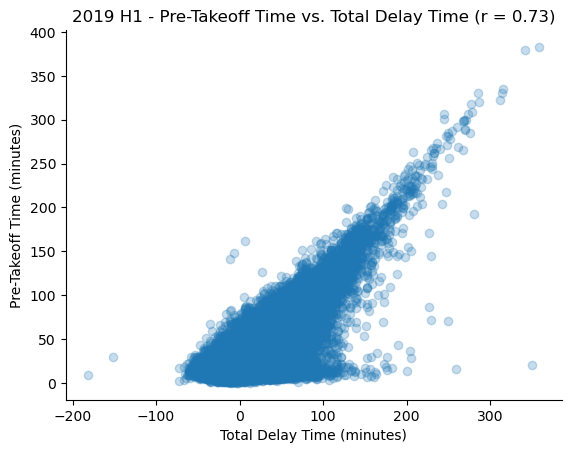

In [66]:
# TOTAL_DELAY, TAXI_OUT - r = 0.53

plt.scatter(all19.TotalDelay, all19.TaxiOut, alpha = 0.25)
plt.xlabel('Total Delay Time (minutes)')
plt.ylabel('Pre-Takeoff Time (minutes)')
plt.title('2019 H1 - Pre-Takeoff Time vs. Total Delay Time (r = 0.73)')
plt.show()

Definitive Shape!

<h3>Pairplots</h3>

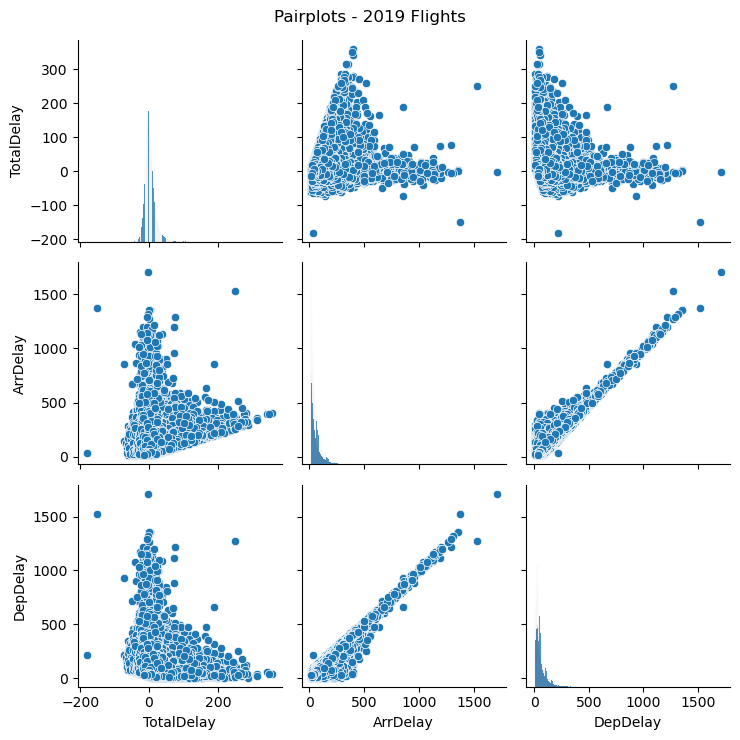

In [69]:
delays = all19[['TotalDelay', 'ArrDelay', 'DepDelay']] #delay
sns.pairplot(delays)
plt.suptitle('Pairplots - 2019 Flights')
plt.tight_layout()
plt.show()

<h3> Line Plots/Time Series </h3>

In [71]:
all19['Month'] = all19['Date'].dt.month

In [72]:
months = all19.groupby(['Month'])[['TotalDelay', 'ArrDelay', 'DepDelay', 'CarrierDelay', 'SecurityDelay', 'NASDelay', 'LateAircraftDelay', 
               'WeatherDelay']].mean().reset_index()

all19[['TotalDelay', 'ArrDelay', 'DepDelay', 'CarrierDelay', 'SecurityDelay', 'NASDelay', 'LateAircraftDelay', 
               'WeatherDelay']]
months

,Month,TotalDelay,ArrDelay,DepDelay,CarrierDelay,SecurityDelay,NASDelay,LateAircraftDelay,WeatherDelay
0,1,3.634076,62.961321,59.327200,17.862897,0.094373,14.318983,27.377173,3.307895
1,2,3.763174,63.602786,59.839565,17.141571,0.084575,13.687834,28.598035,4.090770
2,3,2.869122,59.232198,56.363077,17.741434,0.102633,12.324555,25.883762,3.179815
3,4,3.294530,58.221391,54.926862,18.389201,0.061826,12.954220,24.403655,2.412489
4,5,2.911378,56.871338,53.959959,16.697094,0.083509,12.754466,25.349419,1.986850
5,6,3.968374,63.259252,59.290878,16.115501,0.054368,15.510140,28.139195,3.440048


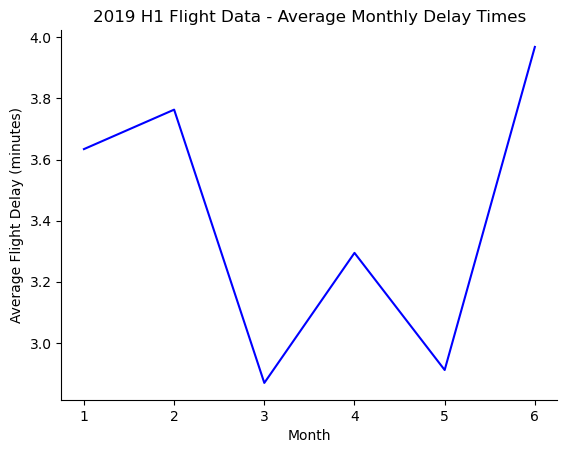

In [73]:
plt.plot(months.Month, months.TotalDelay, color = 'blue')
plt.xlabel('Month')
plt.ylabel('Average Flight Delay (minutes)')
plt.title('2019 H1 Flight Data - Average Monthly Delay Times')
plt.show()

What we found:

- Remember, this is the first half of 2019
- Not much of a pattern in average delay time
- However, all monthly averages are positive

OVERALL Figures to use:

- 2019 H1 TotalDelay x TaxiOut scatterplot
- Flight distribution by airline
- Day of week distribution